In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from numba import njit
from scipy.ndimage import convolve, generate_binary_structure
import utils as ut

# Introduction

In this notebook I reproduce Figure 1 of the paper by Bartelt and Einstein (1986). I have found that my results match closely to their tabulated values of $L^{-15/4} S(0)$, where the square lattice's size is $L\times L$ spins and $S(k)$ is the structure factor along an arbitrary dimension. Note that $L^{-15/4} S(0)$ is the vertical intercept of the plot.

However, my plot superimposes cleanly over Figure 1 only if I plot $2L^{-15/4} S(0)$, ie I include an extra multiplicative factor of 2. Furthermore, the paper's plot has vertical intercepts $L^{-15/4}S(0)\approx0.8$, whereas my own values, which agree with their Table 1, are $\approx0.4$.

I have chosen to take the agreement of my vertical intercept with theirs as evidence of my correct implementation and calculation of structure factor, and I assume that the authors have accidentally including an extra factor of 2 in their plot of Figure 1. 

In [ ]:
# utils.py contains metropolis algorithm for periodic boundary conditions
# this paper uses free boundary conditions

def get_energy(lattice, H=0.0):
    horizontal = -np.sum(lattice[:, :-1] * lattice[:, 1:])
    vertical = -np.sum(lattice[:-1, :] * lattice[1:, :])
    field = -H * lattice.sum()

    return horizontal + vertical + field

@njit 
def metropolis(lattice, steps, BJ, H, energy, save_every=None):

    L = lattice.shape[0]

    if save_every is not None:
        n_frames = steps // save_every + 1
        frames = np.empty((n_frames, L, L), dtype=np.int8)
        frames[0] = lattice
        frame_idx = 1
    else:
        frames = None

    lattice = lattice.copy()
    net_spin = lattice.sum()

    for t in range(0, steps):
        x = np.random.randint(0,L)
        y = np.random.randint(0,L)

        spin = lattice[x,y]

        neighbour_sum = 0
        if x > 0:
            neighbour_sum += lattice[x - 1, y]
        if x < L - 1:
            neighbour_sum += lattice[x + 1, y]
        if y > 0:
            neighbour_sum += lattice[x, y - 1]
        if y < L - 1:
            neighbour_sum += lattice[x, y + 1]

        dE = 2 * spin * (neighbour_sum + H)

        if dE <= 0 or np.random.random() < np.exp(-BJ * dE):
            lattice[x, y] *= -1
            energy += dE
            net_spin -= 2 * spin
        
        if save_every is not None and (t+1) % save_every == 0:
            frames[frame_idx] = lattice
            frame_idx += 1
            
    return lattice, energy, frames

def structure_factor(lattice):
    spin_k = np.fft.fft2(lattice)
    S_k = np.abs(spin_k)**2

    return np.fft.fftshift(S_k)

In [3]:
ratio = 1 # paper starts from an ordered lattice
H = 0.0 # H = mu_s * B / J
BJ = 0.4407 # critical temperature
num_sweeps = 5000000  # each lattice was assigned different num_sweeps in original paper but highest was 5e6

Ls = [12, 18, 24, 30, 48, 60]
burn_in_fraction = 0.1
save_every = 20 # sweeps

In [4]:
all_frames = []

for L in Ls:
    N = L**2
    steps = N * num_sweeps

    burn_in_steps = int(burn_in_fraction * steps)
    equilibration_steps = steps - burn_in_steps

    save_every_steps = save_every * N

    lattice = ut.generate_lattice(L, ratio)
    energy = get_energy(lattice, H)

    # burn-in
    lattice, energy, _ = metropolis(lattice, burn_in_steps, BJ, H, energy)

    # measurement
    _, _, frames = metropolis(lattice, equilibration_steps, BJ, H, energy, save_every_steps)
    all_frames.append(frames)

    print(f"Completed L = {L}")


Completed L = 12
Completed L = 18
Completed L = 24
Completed L = 30
Completed L = 48
Completed L = 60


In [5]:
mean_S_axes = []

for frames in all_frames:
    L = frames.shape[1]
    centre = L // 2

    S_axes = []

    for frame in frames:
        S_k = structure_factor(frame)

        # ky = 0, vary kx
        S_axis = S_k[centre, :]
        S_axes.append(S_axis)

    mean_S_axis = np.mean(S_axes, axis=0)
    mean_S_axes.append(mean_S_axis)

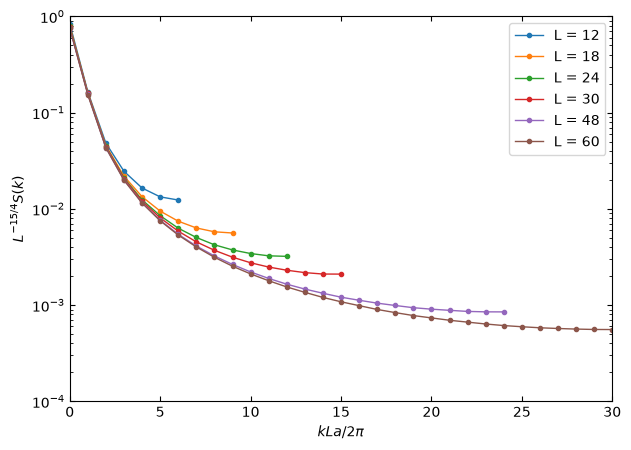

In [ ]:
plt.figure(figsize=(7, 5))

for L, mean_S_axis in zip(Ls, mean_S_axes):

    centre = L // 2

    # k = 0, 1, ..., L/2 - 1
    S_positive = mean_S_axis[centre:]

    # fftshift stores the Nyquist mode k = -pi at index 0
    # S(-pi) = S(pi), so append it as the final positive point
    S_positive = np.append(S_positive, mean_S_axis[0])

    x = np.arange(0, L // 2 + 1)
    y = S_positive * L**(-15/4) * 2 # MULTIPLYING ALL RESULTS BY 2

    plt.semilogy(x, y, 'o-', markersize=3, linewidth=1, label=f"L = {L}")

plt.xlabel(r"$kLa/2\pi$")
plt.ylabel(r"$L^{-15/4}S(k)$")
plt.xlim(0, 30)
plt.ylim(1e-4, 1)
plt.tick_params(which='both', direction='in', top=True, right=True)
plt.legend()
plt.show()

In [7]:
paper_S0 = {
    12: 0.420,
    18: 0.406,
    24: 0.388,
    30: 0.386,
    48: 0.378,
    60: 0.374
}

for L, mean_S_axis in zip(Ls, mean_S_axes):
    centre = L // 2

    simulated = mean_S_axis[centre] * L**(-15/4)

    print(
        f"L = {L}: "
        f"simulation = {simulated:.3f}, "
        f"paper = {paper_S0[L]:.3f}"
    )

L = 12: simulation = 0.421, paper = 0.420
L = 18: simulation = 0.401, paper = 0.406
L = 24: simulation = 0.393, paper = 0.388
L = 30: simulation = 0.385, paper = 0.386
L = 48: simulation = 0.377, paper = 0.378
L = 60: simulation = 0.380, paper = 0.374
